In [3]:
import pandas as pd

# Load Messi's dataset
df = pd.read_csv("data.csv")

# Remove extra spaces from text columns
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].str.strip()

# Fix incorrectly formatted seasons
df["Season"] = df["Season"].replace({
    "11-Dec": "11/12",
    "Dec-13": "12/13"
})

# Convert seasons such as "04/05" into 2004
df["Season_year"] = (
    pd.to_numeric(df["Season"].str.split("/").str[0]) + 2000
)

# Convert goal minutes such as "90+1" into 91
minute_parts = df["Minute"].str.extract(r"^(\d+)(?:\+(\d+))?$")

df["Minute_numeric"] = (
    pd.to_numeric(minute_parts[0])
    + pd.to_numeric(minute_parts[1]).fillna(0)
)

# Check the prepared columns
df[["Season", "Season_year", "Minute", "Minute_numeric"]].head()

,Season,Season_year,Minute,Minute_numeric
0,04/05,2004,90+1,91.0
1,05/06,2005,34,34.0
2,05/06,2005,51,51.0
3,05/06,2005,50,50.0
4,05/06,2005,82,82.0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Input: season year
X = df[["Season_year"]]

# Target: goal minute
y = df["Minute_numeric"]

# Use 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

# Predict goal minutes for the test data
simple_predictions = simple_model.predict(X_test)
print("Test years:", sorted(X_test["Season_year"].unique().tolist()))
print("Simple Linear Regression")
print("MSE:", round(mean_squared_error(y_test, simple_predictions), 2))
print("R²:", round(r2_score(y_test, simple_predictions), 4))

Test years: [2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
Simple Linear Regression
MSE: 674.48
R²: -0.0085


In [6]:
# Convert venue into numbers: home = 1, away = 0
df["Home"] = df["Venue"].map({"H": 1, "A": 0})

# Select two input variables
X_multiple = df[["Season_year", "Home"]]
y = df["Minute_numeric"]

# Keep the same test rows as the previous model
X_train_multiple = X_multiple.loc[X_train.index]
X_test_multiple = X_multiple.loc[X_test.index]

# Train multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train)

# Make predictions
multiple_predictions = multiple_model.predict(X_test_multiple)

# Evaluate the model
print("Multiple Linear Regression")
print("MSE:", round(mean_squared_error(y_test, multiple_predictions), 2))
print("R²:", round(r2_score(y_test, multiple_predictions), 4))

Multiple Linear Regression
MSE: 672.98
R²: -0.0062


In [8]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

# Scale the year, create squared features, then fit regression
polynomial_model = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

# Use the same season-only inputs and split as the first model
polynomial_model.fit(X_train, y_train)

# Predict goal minutes
polynomial_predictions = polynomial_model.predict(X_test)

# Evaluate the model
print("Polynomial Regression")
print("MSE:", round(mean_squared_error(y_test, polynomial_predictions), 2))
print("R²:", round(r2_score(y_test, polynomial_predictions), 4))

Polynomial Regression
MSE: 685.95
R²: -0.0256


In [9]:
# Polynomial regression with two inputs: season and home/away
multiple_polynomial_model = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

# Train using the same rows as the other models
multiple_polynomial_model.fit(X_train_multiple, y_train)

# Predict goal minutes
multiple_polynomial_predictions = multiple_polynomial_model.predict(
    X_test_multiple
)

# Evaluate the model
print("Multivariable Polynomial Regression")
print("MSE:", round(
    mean_squared_error(y_test, multiple_polynomial_predictions), 2
))
print("R²:", round(
    r2_score(y_test, multiple_polynomial_predictions), 4
))

Multivariable Polynomial Regression
MSE: 686.02
R²: -0.0257


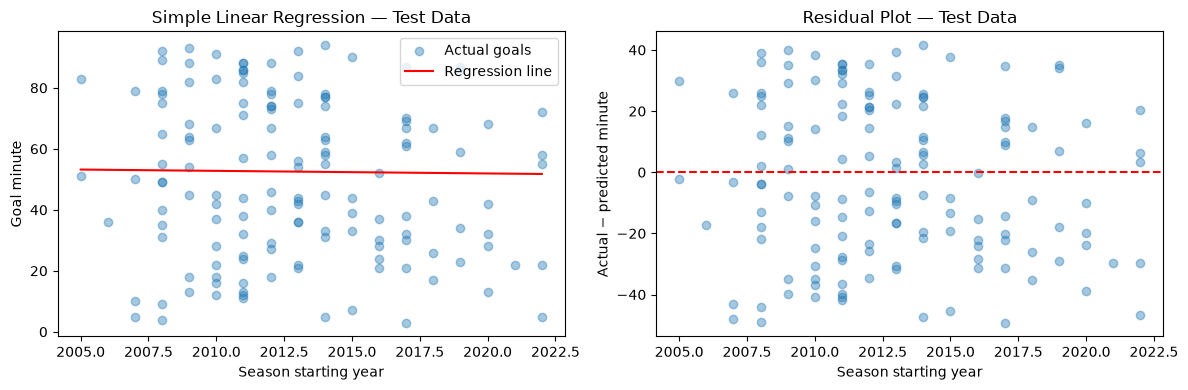

In [10]:
import matplotlib.pyplot as plt

# Sort seasons so the regression line is drawn correctly
sorted_years = X_test["Season_year"].sort_values()

sorted_predictions = simple_model.predict(
    sorted_years.to_frame()
)

# Actual minus predicted goal minute
residuals = y_test - simple_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Actual observations and fitted regression line
axes[0].scatter(
    X_test["Season_year"], y_test,
    alpha=0.4, label="Actual goals"
)
axes[0].plot(
    sorted_years, sorted_predictions,
    color="red", label="Regression line"
)
axes[0].set_title("Simple Linear Regression — Test Data")
axes[0].set_xlabel("Season starting year")
axes[0].set_ylabel("Goal minute")
axes[0].legend()

# 2. Prediction errors
axes[1].scatter(
    X_test["Season_year"], residuals,
    alpha=0.4
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual Plot — Test Data")
axes[1].set_xlabel("Season starting year")
axes[1].set_ylabel("Actual − predicted minute")

plt.tight_layout()
plt.show()

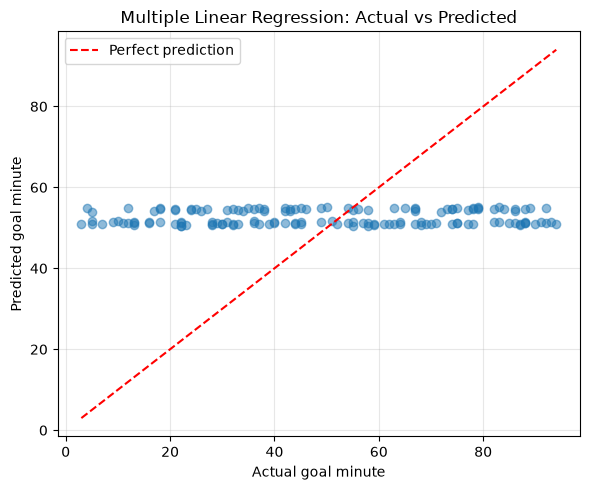

In [11]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test, multiple_predictions, alpha=0.5)

# Perfect predictions would fall on this diagonal
lower = min(y_test.min(), multiple_predictions.min())
upper = max(y_test.max(), multiple_predictions.max())

plt.plot(
    [lower, upper], [lower, upper],
    "r--", label="Perfect prediction"
)

plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.xlabel("Actual goal minute")
plt.ylabel("Predicted goal minute")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Example scenarios within the dataset's season range
examples = pd.DataFrame({
    "Season_year": [2018, 2018, 2020, 2020],
    "Home": [1, 0, 1, 0]
})

# Predict using multiple linear regression
examples["Predicted_minute"] = multiple_model.predict(examples)

# Make the results easier to read
examples["Venue"] = examples["Home"].map({
    1: "Home",
    0: "Away"
})

print(
    examples[
        ["Season_year", "Venue", "Predicted_minute"]
    ].round(2).to_string(index=False)
)

 Season_year Venue  Predicted_minute
        2018  Home             50.76
        2018  Away             54.20
        2020  Home             50.61
        2020  Away             54.05
